# Вентильные рекуррентные сети. Шум и выбросы

**Мотыгуллин Булат Габдулхакович**  
**Группа: Б01-301г**  
**Вариант: 11**

In [1]:
from course import *

seed_all(11)
OUT = ROOT / "results" / "08_lstm_gru_noise"
OUT.mkdir(exist_ok=True, parents=True)

## Общая часть и вариант 11. RNN, LSTM и GRU

Температура Jena climate: часовые наблюдения, окно 24 часа, разбиение по времени. Обучаю пять конфигураций. На test добавляю шум и выбросы только во входы, целевые значения сохраняю.

Источник: Jena climate, первые 3000 часовых наблюдений; окна 24 часа. Train/val/test: 1776 600 600


,model,MAE,RMSE,seconds,parameters
0,RNN_11,0.79967,1.19780,0.61902,673
1,LSTM_11,1.09621,1.73171,1.27012,2617
2,GRU_11,0.86357,1.30402,1.08845,1969
3,LSTM_12,1.16790,1.86516,1.17319,2617
4,GRU_12,0.87002,1.32270,1.08616,1969


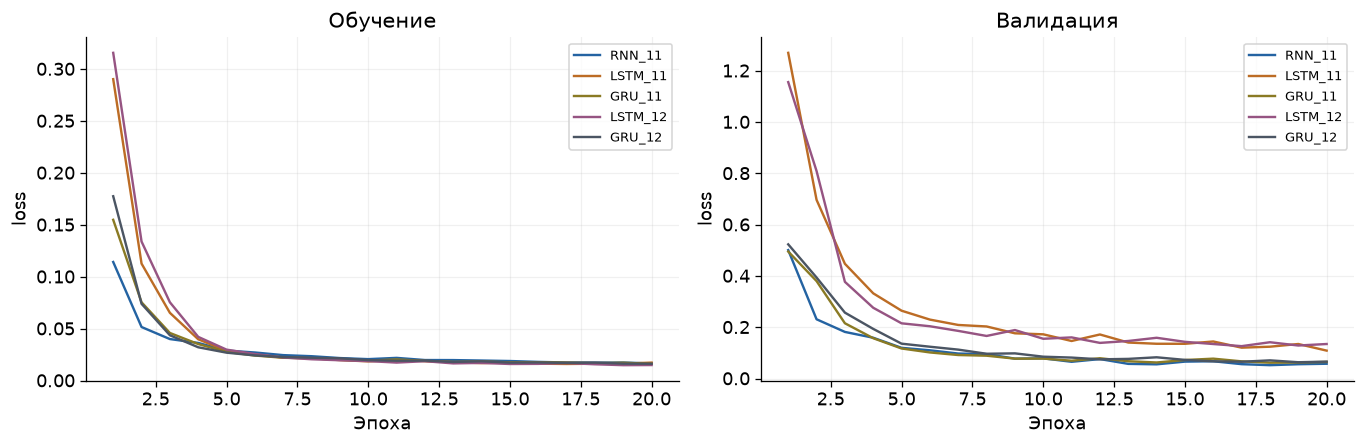

,model,condition,MAE,RMSE
0,RNN_11,clean,1.01331,1.39432
1,RNN_11,noise_0.1,1.12036,1.46142
2,RNN_11,noise_0.3,1.69001,2.08798
3,RNN_11,noise_0.6,2.83980,3.55969
4,RNN_11,outliers_0.02,1.23822,2.26399
5,RNN_11,outliers_0.05,1.73240,3.33565
6,LSTM_11,clean,1.67181,2.39735
7,LSTM_11,noise_0.1,1.73563,2.41675
8,LSTM_11,noise_0.3,2.12169,2.70083
9,LSTM_11,noise_0.6,2.94005,3.58651


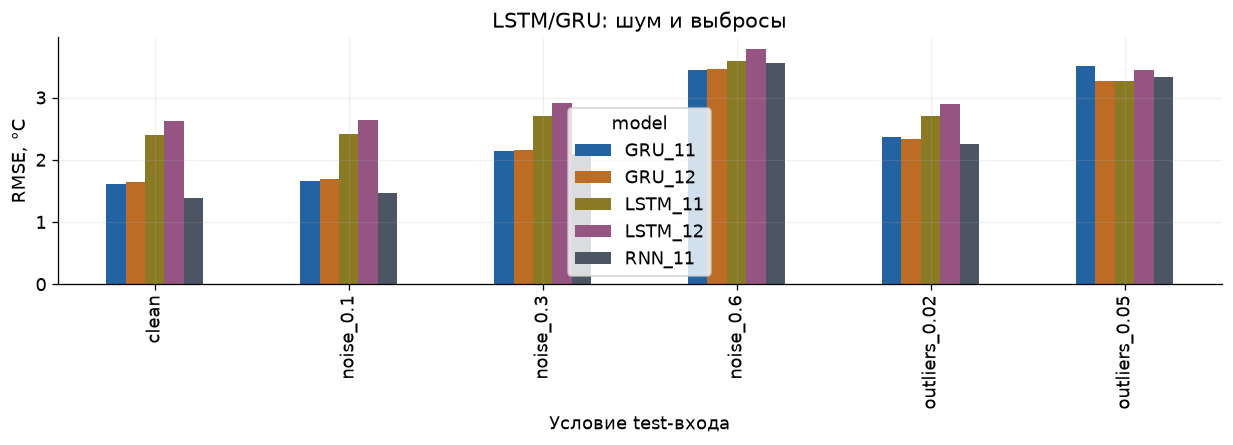

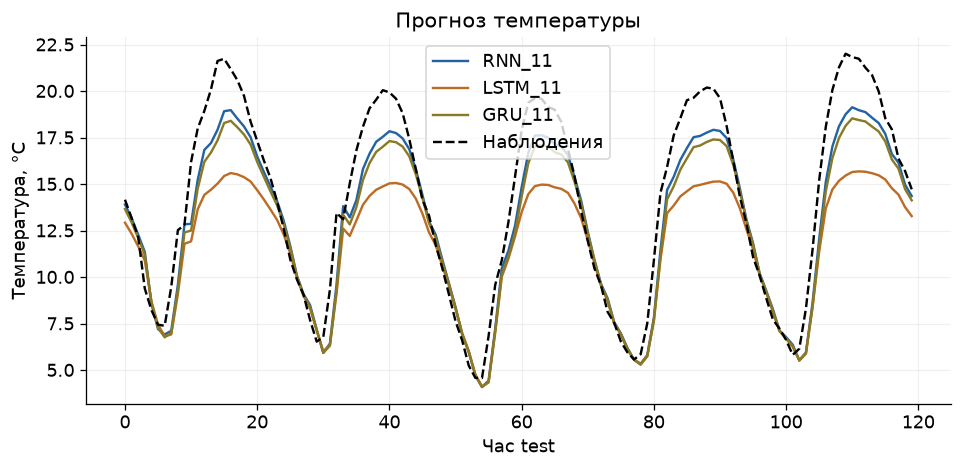

Наивный прогноз test RMSE, °C: 1.2915270740183356


,test_hour,temperature,prediction,absolute_error_C
0,108,21.280001,15.17840,6.10160
1,110,21.830000,15.65021,6.17979
2,352,21.469999,15.27981,6.19019
3,399,21.230000,15.01091,6.21909
4,15,21.740000,15.43482,6.30518
5,109,22.010000,15.46034,6.54967
6,14,21.620001,15.02543,6.59457
7,134,21.940001,15.24953,6.69047
8,421,22.020000,15.26704,6.75296
9,135,22.420000,15.56074,6.85926


Шум добавляю только во входные окна, целевую температуру сохраняю. σ задана в единицах train standard deviation. У LSTM отдельная ячейка памяти, у GRU меньше параметров. Качество сравниваю по таблице.

In [2]:
from sequences import gated_noise

result = gated_noise(OUT)

## Контролируемая проверка долгой зависимости

Задача — запомнить знак первого отсчёта через 10, 40 или 80 шагов с шумом между ними. 360 последовательностей, split 60/20/20. RNN, LSTM и GRU: hidden size = 24, по 50 эпох.

,sequence_length,model,accuracy,macro_f1,seconds
0,10,RNN,1.00000,1.00000,0.12374
1,10,LSTM,1.00000,1.00000,0.23236
2,10,GRU,1.00000,1.00000,0.20746
3,40,RNN,1.00000,1.00000,0.28703
4,40,LSTM,0.50000,0.33333,0.70580
5,40,GRU,0.51389,0.36348,0.61949
6,80,RNN,1.00000,1.00000,0.51432
7,80,LSTM,0.55556,0.50979,1.35821
8,80,GRU,0.56944,0.55915,1.24535


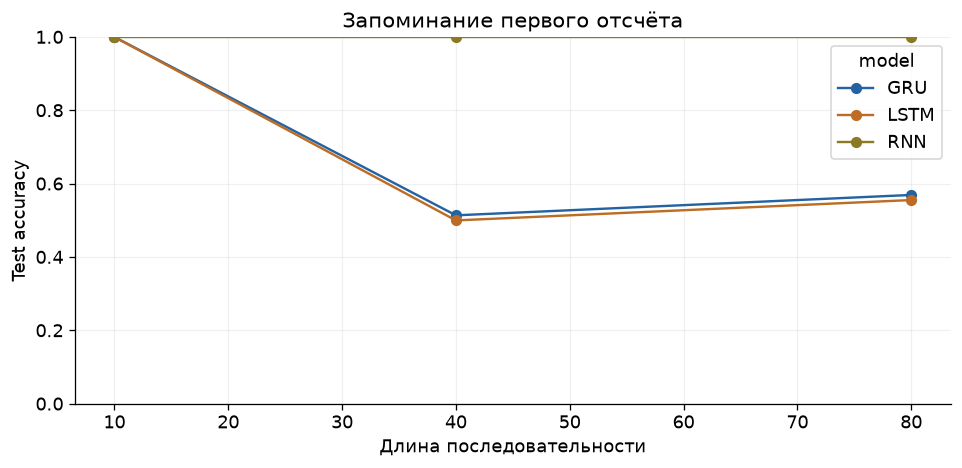

Классификатор должен переносить информацию от первого до последнего шага, промежуточный шум не связан с меткой. Результаты показывают ограничения заданных архитектур, инициализации и бюджета обучения. Неудача LSTM на длинной последовательности возможна: наличие cell state само по себе не гарантирует обучение нужному правилу памяти.

In [3]:
from sequences import SequenceNet

rows = []
for length in [10, 40, 80]:
    rng = np.random.default_rng(11)
    labels = rng.integers(0, 2, 360)
    values = rng.normal(0, 0.03, (360, length, 1)).astype("float32")
    values[:, 0, 0] = 2 * labels - 1
    tr, va, te = split3(values, labels)
    for kind in ["RNN", "LSTM", "GRU"]:
        seed_all()
        m = SequenceNet(kind, hidden=24, outputs=2)
        m, h, t = fit(m, tr, va, epochs=50, lr=0.003)
        metrics, _, _ = classify(m, te)
        rows.append({"sequence_length": length, "model": kind, **metrics, "seconds": t})
df = table(rows, OUT, "long_dependency")
df.pivot(index="sequence_length", columns="model", values="accuracy").plot(marker="o")
plt.xlabel("Длина последовательности")
plt.ylabel("Test accuracy")
plt.ylim(0, 1)
plt.title("Запоминание первого отсчёта")
showfig("long_dependency", OUT)
note(
    "Классификатор должен переносить информацию от первого до последнего шага, промежуточный шум не связан с меткой. Результаты показывают ограничения заданных архитектур, инициализации и бюджета обучения. Неудача LSTM на длинной последовательности возможна: наличие cell state само по себе не гарантирует обучение нужному правилу памяти."
)

## Память, горизонты и генерация

Проверяю размеры состояний LSTM и GRU, сравниваю рекурсивный прогноз с прогнозом по истинной истории. Генерация музыки — в 10_music_generation.ipynb.

In [4]:
m = result["models"]["LSTM_11"]
sample = result["test"][0][:2]
output, (hidden, cell) = m.core(sample)
print("LSTM sequence:", output.shape, "hidden:", hidden.shape, "cell:", cell.shape)
gm = result["models"]["GRU_11"]
gout, gh = gm.core(sample)
print("GRU sequence:", gout.shape, "hidden:", gh.shape)
rows = []
for horizon in [1, 6, 12, 24]:
    errors = []
    for i in range(0, 200 - horizon, 10):
        window = result["test"][0][i : i + 1].clone()
        with torch.no_grad():
            for j in range(horizon):
                p = m(window)
                window = torch.cat([window[:, 1:], p[:, None]], 1)
        errors.append(
            (p.item() - result["test"][1][i + horizon - 1].item())
            * result["meta"]["std"]
        )
    rows.append(
        {"horizon_hours": horizon, "RMSE_C": np.sqrt(np.mean(np.square(errors)))}
    )
table(rows, OUT, "multi_step_horizon")
note(
    "В closed-loop режиме ошибки собственных прогнозов попадают обратно во вход. Отдельное cell state помогает LSTM переносить информацию, но не гарантирует устойчивого длинного прогноза. В таблице показан рост или изменение ошибки с горизонтом на выбранных тестовых фрагментах."
)

LSTM sequence: torch.Size([2, 24, 24]) hidden: torch.Size([1, 2, 24]) cell: torch.Size([1, 2, 24])
GRU sequence: torch.Size([2, 24, 24]) hidden: torch.Size([1, 2, 24])


,horizon_hours,RMSE_C
0,1,2.76567
1,6,6.93685
2,12,7.88958
3,24,6.70709


В closed-loop режиме ошибки собственных прогнозов попадают обратно во вход. Отдельное cell state помогает LSTM переносить информацию, но не гарантирует устойчивого длинного прогноза. В таблице показан рост или изменение ошибки с горизонтом на выбранных тестовых фрагментах.

## Ответы на контрольные вопросы

1. Forget gate масштабирует сохранённое cell state и управляет объёмом прежней информации, перенесённой дальше.

2. Аддитивный путь cell state и управляемые вентили помогают градиенту проходить через время, хотя длительный контекст сохраняется не всегда.

3. GRU объединяет память и скрытое состояние, используя update/reset gates и обычно меньше параметров.

4. Собственные неточные прогнозы подаются обратно во вход и изменяют распределение последующих состояний.

5. Деление logits на temperature<1 делает выбор более сосредоточенным; temperature>1 повышает случайность.